In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

import lightgbm as lgb
import xgboost as xgb
import shap

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

#### In this notebook, for flow cleanliness we will be solely modelating using the proposed models in the paper, only with the 9 features.

In [5]:
df= pd.read_csv("/Users/tam_pr/research/eda/k_9_df.csv")

In [6]:
df

,CS,ZP,MW,Mla,AWCe,AWLa,Mce,MCN,La,group_id,AA
0,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,5,41.142363
1,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,5,41.077538
2,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,6,58.634350
3,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,6,58.439875
4,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,6,58.688371
...,...,...,...,...,...,...,...,...,...,...,...
170,5.687981,28.91,171.9932,0.001163,4.544342,0.50352,0.010466,0.011628,1.933542,43,84.171000
171,5.687981,28.91,171.9932,0.001163,4.544342,0.50352,0.010466,0.011628,1.933542,43,84.993000
172,5.687981,28.91,171.9932,0.001163,4.544342,0.50352,0.010466,0.011628,1.933542,44,84.805100
173,5.687981,28.91,171.9932,0.001163,4.544342,0.50352,0.010466,0.011628,1.933542,44,84.758100


In [7]:
X= df.copy()
X.drop(columns=["group_id","AA"], inplace=True)
y = df["AA"].copy()

In [8]:
X.shape

(175, 9)

In [9]:
y.shape

(175,)

In [10]:
splitter = GroupShuffleSplit(n_splits=1, test_size= 0.2, random_state= 1234)
train_indices, test_indices = next(splitter.split(X = X, y = y, groups = df["group_id"]))
X_train , X_test = X.iloc[train_indices], X.iloc[test_indices]
y_train , y_test = y.iloc[train_indices], y.iloc[test_indices]

In [11]:
group_id_train = df["group_id"].iloc[train_indices]

#### Cross Validation

In [12]:
folds = list(GroupKFold(n_splits=5).split(X_train, y_train, groups= group_id_train))

In [13]:
len(folds)

5

#### Now that we have succesfully splitted our training data into 5 folds, we can now begin to test the four selected models

## RandomForestRegressor

In [14]:
cv = GroupKFold(n_splits=5)

,Model,Fold,R2,MAE
0,Random Forest,1,0.4864,11.3816
1,Random Forest,2,0.1268,16.8180
2,Random Forest,3,0.2752,18.0615
3,Random Forest,4,0.2595,11.8621
4,Random Forest,5,0.4642,9.8300


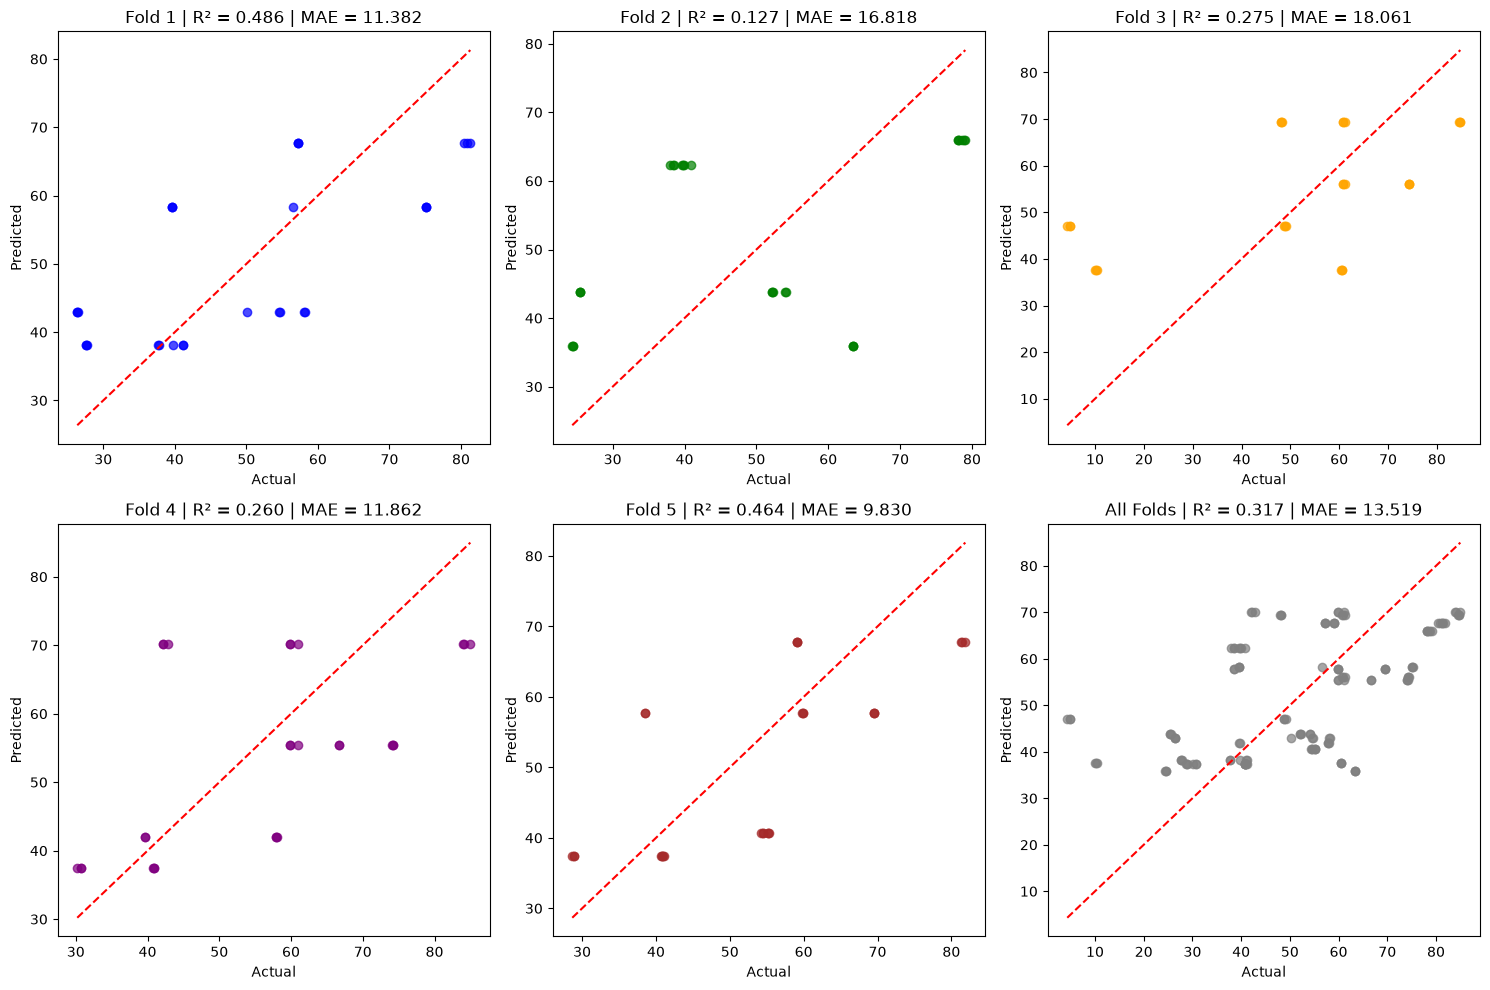

In [ ]:
fold_results = []

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

colors = ["blue", "green", "orange", "purple", "brown"]

all_y_actual = []
all_y_pred = []

for fold, (fold_train_idx, fold_val_idx) in enumerate(folds, start=1):
    X_fold_train = X_train.iloc[fold_train_idx]
    y_fold_train = y_train.iloc[fold_train_idx]

    X_fold_val = X_train.iloc[fold_val_idx]
    y_fold_val = y_train.iloc[fold_val_idx]

    model = RandomForestRegressor(random_state=1234)
    model.fit(X_fold_train, y_fold_train)

    y_pred = model.predict(X_fold_val)

    all_y_actual.extend(y_fold_val)
    all_y_pred.extend(y_pred)

    r2 = r2_score(y_fold_val, y_pred)
    mae = mean_absolute_error(y_fold_val, y_pred)

    fold_results.append({
    "Model": "Random Forest",
    "Fold": fold,
    "R2": r2,
    "MAE": mae
    })

    axes[fold - 1].scatter(
        y_fold_val, y_pred,
        alpha=0.7,
        color=colors[fold - 1]
    )

    min_val = min(y_fold_val.min(), y_pred.min())
    max_val = max(y_fold_val.max(), y_pred.max())

    axes[fold - 1].plot(
        [min_val, max_val], [min_val, max_val], "r--"
    )

    axes[fold - 1].set_title(
        f"Fold {fold} | R² = {r2:.3f} | MAE = {mae:.3f}"
    )
    axes[fold - 1].set_xlabel("Actual")
    axes[fold - 1].set_ylabel("Predicted")


fold_results_table = pd.DataFrame(fold_results)

# All folds combined
axes[5].scatter(
    all_y_actual, all_y_pred,
    alpha=0.7, color="gray"
)

min_val = min(min(all_y_actual), min(all_y_pred))
max_val = max(max(all_y_actual), max(all_y_pred))

axes[5].plot(
    [min_val, max_val], [min_val, max_val], "r--"
)

axes[5].set_title(
    f"All Folds | R² = {r2_score(all_y_actual, all_y_pred):.3f} "
    f"| MAE = {mean_absolute_error(all_y_actual, all_y_pred):.3f}"
)
axes[5].set_xlabel("Actual")
axes[5].set_ylabel("Predicted")

plt.tight_layout()
plt.show()


In [31]:
display(fold_results_table.round(4))

,Model,Fold,R2,MAE
0,Random Forest,1,0.4864,11.3816
1,Random Forest,2,0.1268,16.8180
2,Random Forest,3,0.2752,18.0615
3,Random Forest,4,0.2595,11.8621
4,Random Forest,5,0.4642,9.8300


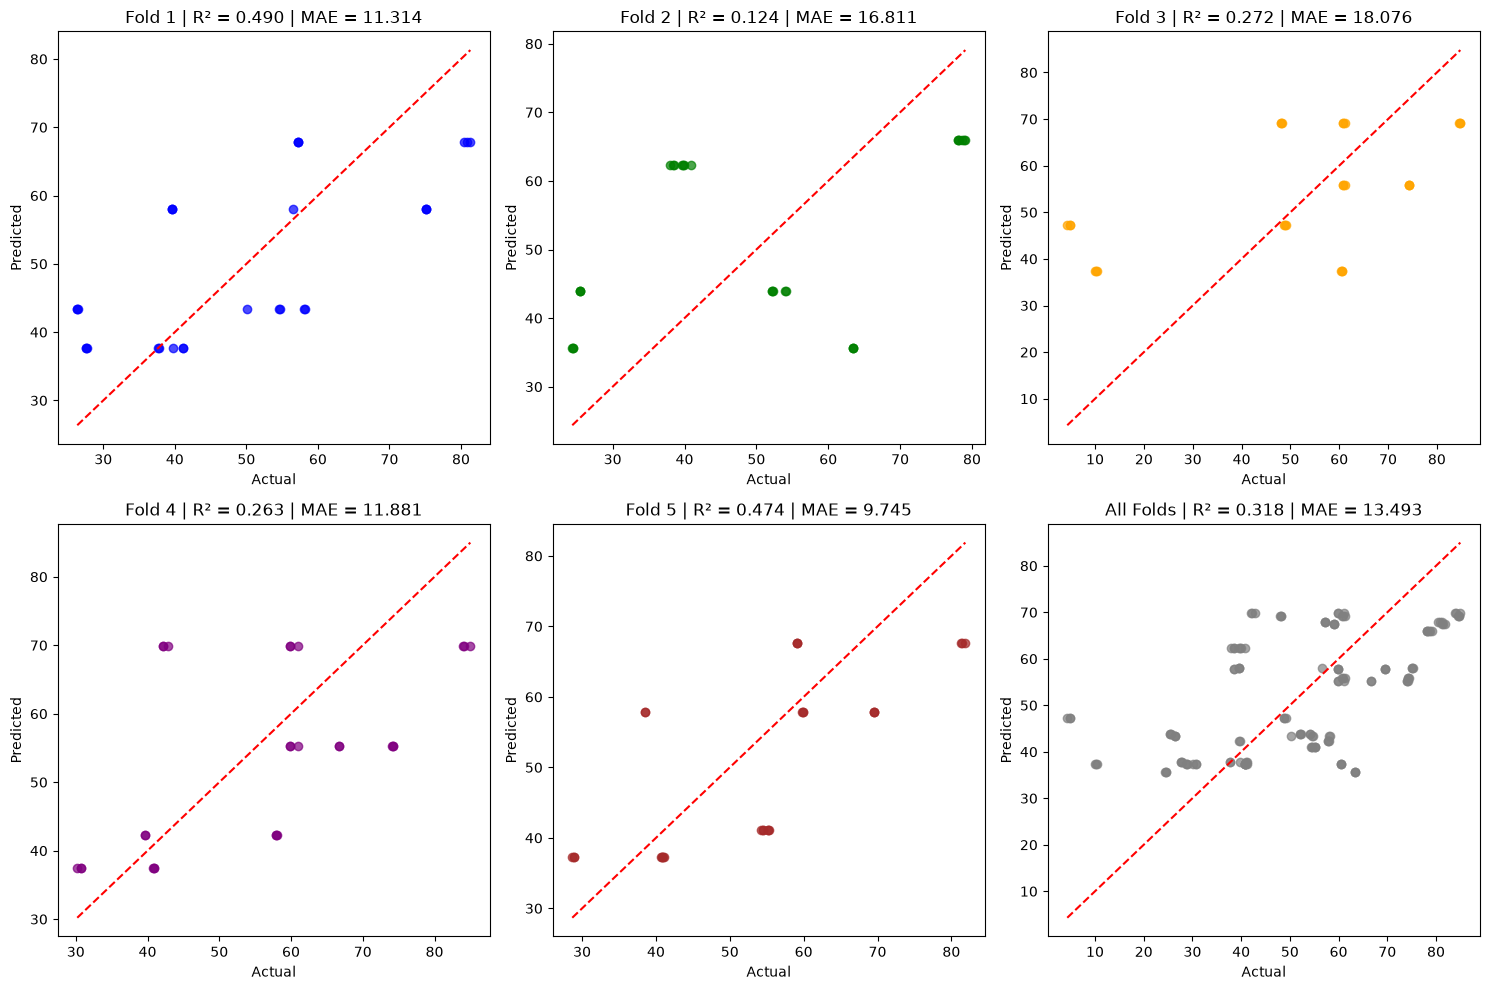

In [32]:
fold_results_2 = []

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

colors = ["blue", "green", "orange", "purple", "brown"]

all_y_actual_2 = []
all_y_pred_2 = []

for fold, (fold_train_idx, fold_val_idx) in enumerate(folds, start=1):
    X_fold_train = X_train.iloc[fold_train_idx]
    y_fold_train = y_train.iloc[fold_train_idx]

    X_fold_val = X_train.iloc[fold_val_idx]
    y_fold_val = y_train.iloc[fold_val_idx]

    model_2 = ExtraTreesRegressor(random_state=1234)
    model_2.fit(X_fold_train, y_fold_train)

    y_pred_2 = model_2.predict(X_fold_val)

    all_y_actual_2.extend(y_fold_val)
    all_y_pred_2.extend(y_pred_2)

    r2_2 = r2_score(y_fold_val, y_pred_2)
    mae_2 = mean_absolute_error(y_fold_val, y_pred_2)

    fold_results_2.append({
        "Model": "Extra Trees Regressor",
        "Fold": fold,
        "R2": r2_2,
        "MAE": mae_2
    })

    axes[fold - 1].scatter(
        y_fold_val, y_pred_2,
        alpha=0.7,
        color=colors[fold - 1]
    )

    min_val = min(y_fold_val.min(), y_pred_2.min())
    max_val = max(y_fold_val.max(), y_pred_2.max())

    axes[fold - 1].plot(
        [min_val, max_val], [min_val, max_val], "r--"
    )

    axes[fold - 1].set_title(
        f"Fold {fold} | R² = {r2_2:.3f} | MAE = {mae_2:.3f}"
    )
    axes[fold - 1].set_xlabel("Actual")
    axes[fold - 1].set_ylabel("Predicted")

fold_results_table_2 = pd.DataFrame(fold_results_2)

# All folds combined
axes[5].scatter(
    all_y_actual_2, all_y_pred_2,
    alpha=0.7, color="gray"
)

min_val = min(min(all_y_actual_2), min(all_y_pred_2))
max_val = max(max(all_y_actual_2), max(all_y_pred_2))

axes[5].plot(
    [min_val, max_val], [min_val, max_val], "r--"
)

axes[5].set_title(
    f"All Folds | R² = {r2_score(all_y_actual_2, all_y_pred_2):.3f} "
    f"| MAE = {mean_absolute_error(all_y_actual_2, all_y_pred_2):.3f}"
)
axes[5].set_xlabel("Actual")
axes[5].set_ylabel("Predicted")

plt.tight_layout()
plt.show()



In [33]:
display(fold_results_table_2.round(4))

,Model,Fold,R2,MAE
0,Extra Trees Regressor,1,0.4902,11.3139
1,Extra Trees Regressor,2,0.1235,16.8115
2,Extra Trees Regressor,3,0.2722,18.0757
3,Extra Trees Regressor,4,0.2628,11.8809
4,Extra Trees Regressor,5,0.4738,9.7446


In [34]:
print("Distinct feature rows:", X.drop_duplicates().shape)
print("Distinct MW values:", X["MW"].nunique())

# Step 1: Material-mean baseline, using the same folds
baseline_results_3 = []

for fold, (fold_train_idx, fold_val_idx) in enumerate(folds, start=1):
    X_fold_train = X_train.iloc[fold_train_idx]
    y_fold_train = y_train.iloc[fold_train_idx]

    X_fold_val = X_train.iloc[fold_val_idx]
    y_fold_val = y_train.iloc[fold_val_idx]

    # Calculate each material's mean AA using training rows only
    material_means = y_fold_train.groupby(
        X_fold_train["MW"]
    ).mean()

    # Predict using the corresponding material mean
    y_pred_3 = X_fold_val["MW"].map(material_means)

    # Handle any material not present in the training fold
    y_pred_3 = y_pred_3.fillna(y_fold_train.mean())

    r2_3 = r2_score(y_fold_val, y_pred_3)
    mae_3 = mean_absolute_error(y_fold_val, y_pred_3)

    baseline_results_3.append({
        "Fold": fold,
        "Baseline R2": r2_3,
        "Baseline MAE": mae_3
    })

baseline_table_3 = pd.DataFrame(baseline_results_3)

# Step 2: Compare against the existing Extra Trees results
et_table_3 = fold_results_table_2[
    ["Fold", "R2", "MAE"]
].rename(columns={
    "R2": "ET R2",
    "MAE": "ET MAE"
})

comparison_table_3 = baseline_table_3.merge(
    et_table_3,
    on="Fold"
)

display(comparison_table_3.round(4))


Distinct feature rows: (4, 9)
Distinct MW values: 4


,Fold,Baseline R2,Baseline MAE,ET R2,ET MAE
0,1,0.4902,11.3139,0.4902,11.3139
1,2,0.1235,16.8115,0.1235,16.8115
2,3,0.2722,18.0757,0.2722,18.0757
3,4,0.2628,11.8809,0.2628,11.8809
4,5,0.4738,9.7446,0.4738,9.7446


### Why we stop the k = 9 vs k = 10 exploration

The single-split Adjusted R² sweep was too unstable to justify k = 10, so we planned to compare k = 9 against k = 10 directly. Before running k = 10 we found that this comparison cannot be informative: all the selected features (CS, ZP, MW, Mla, AWCe, AWLa, Mce, MCN, La, and CO for k = 10) are batch-level constants, so X only contains 4 distinct rows, one per material (X.drop_duplicates().shape = (4, 9)).

Consequently, a tree model on these features is equivalent to predicting each material’s mean AA. We verified this: a material-mean baseline reproduces Extra Trees’ per-fold R² and MAE exactly (mean R² ≈ 0.32, MAE ≈ 13.6, against 0.862 and 4.04 with all 24 features). k = 10 adds only CO, another per-material constant, so it would give identical predictions.

The univariate F-score ranks material-level features highest and Conc and the Method dummies lowest, so any top-k set loses the information that drives the model’s performance (assay method and concentration). The paper’s own final model uses all 26 features (Fig. 10), which carry the same information as our 24. We therefore continue with all 24 features, and keep the 9-feature model as an ablation showing how much material identity alone explains.

Consequently, a tree model on these features is equivalent to a lookup table with 4 entries: for every row, it predicts the mean AA of that row’s material, computed from the training rows (the 4 values below). We verified this: a material-mean baseline reproduces Extra Trees’ per-fold R² and MAE exactly (mean R² ≈ 0.32, MAE ≈ 13.6, against 0.862 and 4.04 with all 24 features). Because AA varies a lot within each material depending on assay method and concentration, which the model cannot see, much of the variance is left unexplained.